In [1]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


# Load the Dataset 

In [2]:
df=pd.read_csv("C:\\Users\\Dell\\Desktop\\Titanic Survival Analysis\\Data for analysis\\titanic.csv")

In [3]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


# Inspect Data

In [4]:
#Columns Name
df.columns.tolist()

['PassengerId',
 'Survived',
 'Pclass',
 'Name',
 'Sex',
 'Age',
 'SibSp',
 'Parch',
 'Ticket',
 'Fare',
 'Cabin',
 'Embarked']

In [5]:
df.shape

(891, 12)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB


In [7]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [8]:
df.duplicated()

0      False
1      False
2      False
3      False
4      False
       ...  
886    False
887    False
888    False
889    False
890    False
Length: 891, dtype: bool

In [9]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [10]:
df.dtypes

PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object

# Handling missing data

In [11]:
#work on copy data
df=df.copy()

In [12]:
if "Age" in df.columns:
    df["Age"]=df["Age"].fillna(df["Age"].mean()) #Filling age with mean value

# Fill missing embarkation port with the mode
if "Embarked" in df.columns and df["Embarked"].notna().any():
    df["Embarked"] = df["Embarked"].fillna(
        df["Embarked"].mode()[0]
    )


In [13]:
# Fill missing cabin values with "Unknown"
df["Cabin"] = df["Cabin"].fillna("Unknown")

# Check missing values
print(df["Cabin"].isnull().sum())

# Check the column
print(df["Cabin"].value_counts().head())

0
Cabin
Unknown        687
G6               4
C23 C25 C27      4
B96 B98          4
F33              3
Name: count, dtype: int64


In [14]:
df["Cabin"].isnull().sum()

np.int64(0)

In [15]:

# Cabin has many missing values in the common dataset
if "Cabin" in df.columns:
    df["CabinKnown"] = df["Cabin"].notna().astype(int)

In [16]:
df.isnull().sum()

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Cabin          0
Embarked       0
CabinKnown     0
dtype: int64

# Feature Engineering

In [17]:
# Create family size
if {"SibSp", "Parch"}.issubset(df.columns):
    df["FamilySize"] = df["SibSp"] + df["Parch"] + 1


In [18]:
# Create travelling-alone feature
if "FamilySize" in df.columns:
    df["IsAlone"] = (df["FamilySize"] == 1).astype(int)


In [19]:
# Extract title from passenger name
if "Name" in df.columns:
    df["Title"] = df["Name"].str.extract(
        r",\s*([^.]*)\."
    )[0].str.strip()

In [20]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,CabinKnown,FamilySize,IsAlone,Title
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,Unknown,S,1,2,0,Mr
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,1,2,0,Mrs
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,Unknown,S,1,1,1,Miss
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,1,2,0,Mrs
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,Unknown,S,1,1,1,Mr


In [21]:
%pip install openpyxl


Note: you may need to restart the kernel to use updated packages.


In [22]:
import os

# Create the csv folder if it doesn't exist
os.makedirs("csv", exist_ok=True)

# Save the updated dataset
df.to_csv("data for analysis/titanic_updated.csv", index=False)

print("CSV file created successfully!")
print("Location:", os.path.abspath("csv/titanic_updated.csv"))
print("Rows and columns:", df.shape)

CSV file created successfully!
Location: C:\Users\Dell\Desktop\Titanic Survival Analysis\csv\titanic_updated.csv
Rows and columns: (891, 16)


# Exploratory Data Analysis (EDA)

In [23]:
#OVERALLCSURVIVAL RATE

survival_counts = df["Survived"].value_counts().sort_index()

survival_counts.index = ["Did not survive", "Survived"]
print(survival_counts)

survival_rate = df["Survived"].mean() * 100
print(f"Survival rate: {survival_rate:.2f}%")

Did not survive    549
Survived           342
Name: count, dtype: int64
Survival rate: 38.38%


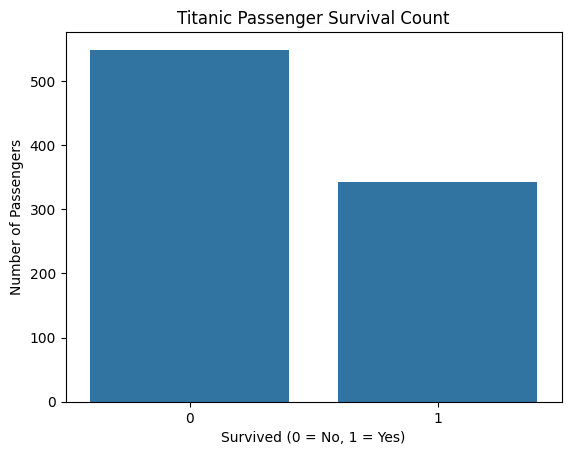

In [24]:
sns.countplot(data=df, x="Survived")
plt.title("Titanic Passenger Survival Count")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")
plt.show()

In [25]:
#SURVIVAL BY SEX

survival_by_sex=df.groupby("Sex")["Survived"].agg(["count","sum","mean"])
survival_by_sex.columns=["Passengers","Survivors","SurvivalRate"]
survival_by_sex["SurvivalRate"]*=100
print(survival_by_sex.round(2))

        Passengers  Survivors  SurvivalRate
Sex                                        
female         314        233         74.20
male           577        109         18.89


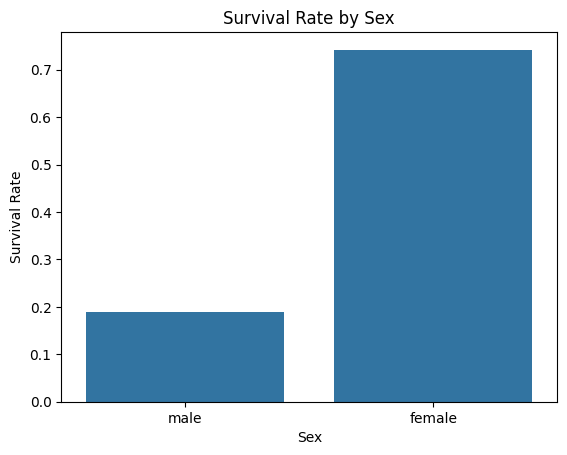

In [26]:
sns.barplot(data=df,x="Sex",y="Survived",errorbar=None)
plt.title("Survival Rate by Sex")
plt.ylabel("Survival Rate")
plt.show()

In [27]:
#SURVIVAL BY PASSENGER CLASS

df.groupby("Pclass")["Survived"].agg(["count","sum","mean"]).round(3)

,count,sum,mean
Pclass,,,
1,216,136,0.630
2,184,87,0.473
3,491,119,0.242


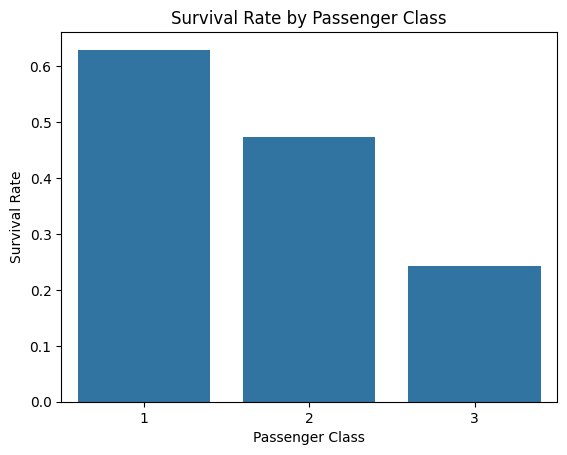

In [28]:
sns.barplot(data=df, x="Pclass",y="Survived",errorbar=None)
plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate")
plt.show()

In [29]:
df.groupby("Survived")["Age"].agg(["mean","median","min","max"]).round(2)

,mean,median,min,max
Survived,,,,
0,30.42,29.7,1.00,74.0
1,28.55,29.7,0.42,80.0


          count   mean
Embarked              
C           168  0.554
Q            77  0.390
S           646  0.339


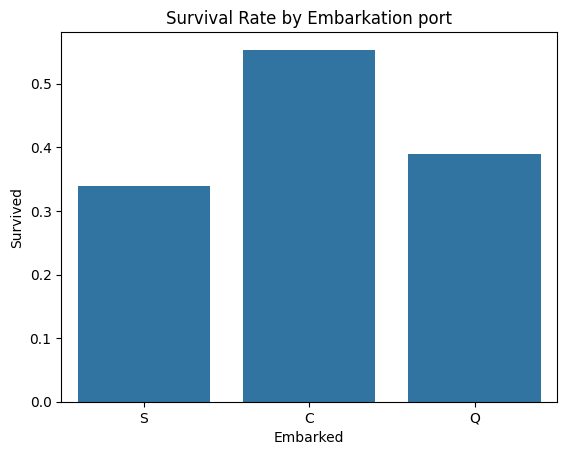

In [30]:
#SURVIVAL BY EMBARKATION PORT

if "Embarked" in df.columns:
    print(df.groupby("Embarked",dropna=False)["Survived"].agg(["count","mean"]).round(3))
    sns.barplot(data=df,x="Embarked",y="Survived",errorbar=None)
    plt.title("Survival Rate by Embarkation port")
    plt.show()

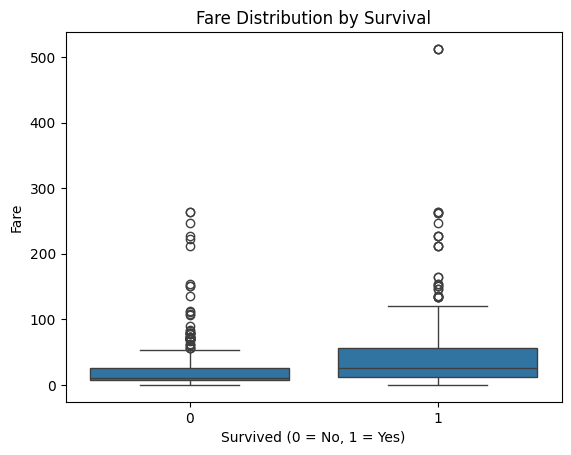

           mean  median
Survived               
0         22.12    10.5
1         48.40    26.0


In [31]:
# SURVIVAL BR FARE
sns.boxplot(data=df, x="Survived", y="Fare")
plt.title("Fare Distribution by Survival")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.show()


print(
    df.groupby("Survived")["Fare"]
      .agg(["mean", "median"])
      .round(2)
)

            count   mean
FamilySize              
1             537  0.304
2             161  0.553
3             102  0.578
4              29  0.724
5              15  0.200
6              22  0.136
7              12  0.333
8               6  0.000
11              7  0.000


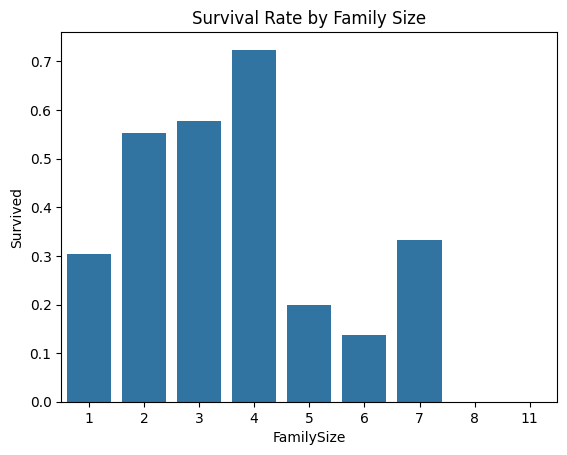

In [32]:
#FAMIL SIZE AND SURVIVAL

if "FamilySize" in df.columns:
    print(
        df.groupby("FamilySize")["Survived"]
          .agg(["count", "mean"])
          .round(3)
    )

    sns.barplot(
        data=df, x="FamilySize", y="Survived",
        errorbar=None
    )
    plt.title("Survival Rate by Family Size")
    plt.show()

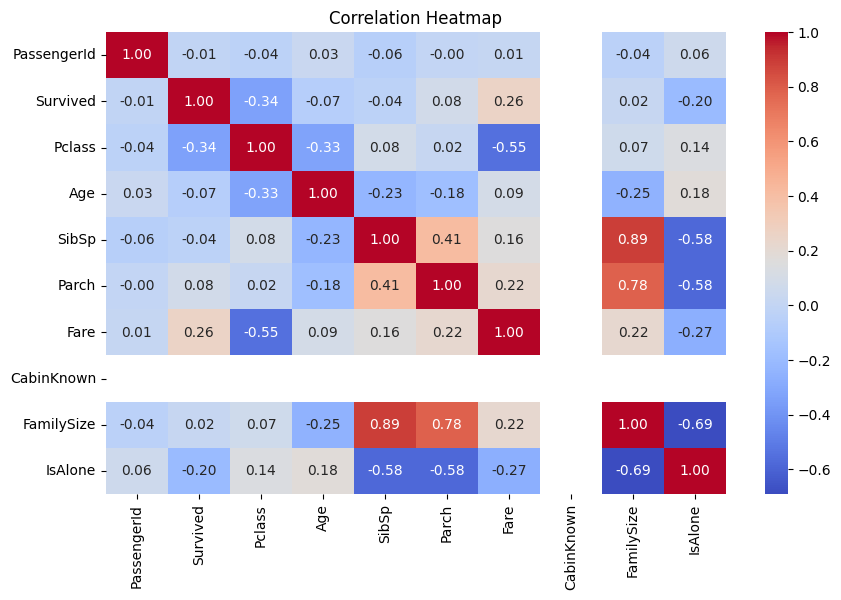

In [33]:
# CORRELATION BETWEEN NUMERICAL VARIABLES

numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(10, 6))
sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Heatmap")
plt.show()

In [34]:
# Build a summary of your findings

print("Total passengers:", len(df))
print("Survivors:", int(df["Survived"].sum()))
print("Non-survivors:", int((df["Survived"] == 0).sum()))
print(
    "Overall survival rate:",
    round(df["Survived"].mean() * 100, 2), "%"
)

if "Sex" in df.columns:
    print("\nSurvival rate by sex:")
    print((df.groupby("Sex")["Survived"].mean() * 100).round(2))

if "Pclass" in df.columns:
    print("\nSurvival rate by class:")
    print((df.groupby("Pclass")["Survived"].mean() * 100).round(2))

Total passengers: 891
Survivors: 342
Non-survivors: 549
Overall survival rate: 38.38 %

Survival rate by sex:
Sex
female    74.20
male      18.89
Name: Survived, dtype: float64

Survival rate by class:
Pclass
1    62.96
2    47.28
3    24.24
Name: Survived, dtype: float64


# Statical analysis

In [35]:
print("Mean age:", df["Age"].mean())
print("Median age:", df["Age"].median())
print("Age standard deviation:", df["Age"].std())

Mean age: 29.69911764705882
Median age: 29.69911764705882
Age standard deviation: 13.002015226002882


In [36]:
from scipy.stats import chi2_contingency

table = pd.crosstab(df["Sex"], df["Survived"])

chi2, p_value, dof, expected = chi2_contingency(table)

print("Chi-square statistic:", chi2)
print("Degrees of freedom:", dof)
print("P-value:", p_value)

Chi-square statistic: 260.71702016732104
Degrees of freedom: 1
P-value: 1.1973570627755645e-58
